# Demand Model

## Define Assumptions for the Demand Model

1. **October–December 2025.** Keep these records in the coverage audit. Exclude weeks and trailing windows overlapping the reported gap from baseline evaluation. The report cites unusually low customer coverage. This is a provisional coverage decision.
2. **Elasticity.** The report's US −2.45 and CA −1.63 are provisional market-level demo inputs. Use −0.3 and −5 as sensitivity cases. SKU → family → segment × product type remains the intended fallback when the corresponding estimates are available. The report provides no SKU-level coefficient table.
3. **Recommendation cohort.** Freeze the output cohort as of August 23, 2026. Include SKUs with a positive invoice sale in the prior 30 calendar days through that date. All eligible SKUs remain in the output population. Candidate forecasts require usable pre-cutoff inputs. The historical backtest selects eligible rows as of each forecast date.
4. **Timing and currency.** Use Monday cutoffs and local-currency invoice ASP. Require shipment before the cutoff for historical feature inputs as a proxy for visibility. Actual invoice availability timestamps still need confirmation. The date-based cohort and forecast inputs serve different purposes.
5. **Missing observations.** Keep missing sales weeks out of evaluation unless stock and listing coverage establish that they are true zeros. Forecast scores therefore describe weeks with recorded sales.

[Pricewise_Update_Elasticity_Seasonality_Event.docx](Pricewise_Update_Elasticity_Seasonality_Event.docx) · [Reference_Price_Exploration.ipynb](Reference_Price_Exploration.ipynb)

## Filter Invoices for the Demand Model

**Why we filter.** The demand model uses completed sales to measure units sold and average selling price. 

**Filter rules.** Keep US and Canadian invoice lines for **Enterprise or Personal** customers and **Notebook, Desktop, or Workstations**. Each line must have a SKU ID, an order date on or before **August 23, 2026**, positive invoice quantity, and positive invoice revenue in local currency. [Pricewise_Update_Elasticity_Seasonality_Event.docx](Pricewise_Update_Elasticity_Seasonality_Event.docx), [initial_EDA]()

**Results.** The filters retain **1,527,601 US invoice lines** and **314,314 Canadian invoice lines**. The monthly audit confirms that customer IDs fell from **418 to 3 in the US** and from **62 to 2 in Canada** between September and October 2025. Those low counts persist through December. The next section applies the 30-day sales filter and identifies **473 US SKUs** and **406 Canadian SKUs** for the recent-sales cohort.

In [30]:
import numpy as np
import pandas as pd
from pathlib import Path

MARKETS = ("US", "CA")
SEGMENTS = ("Enterprise", "Personal")
TYPES = ("Notebook", "Desktop", "Workstations")
AS_OF = pd.Timestamp("2026-08-23")
GAP_START, GAP_END = pd.Timestamp("2025-10-01"), pd.Timestamp("2026-01-01")
KEY = ["country", "product_id", "segment", "product_type"]
FIELDS = KEY + [
    "order_date", "ship_date", "customer_id", "product_family",
    "invoice_quantity", "invoice_revenue_country_currency",
]
daily_parts, coverage_parts, counts = [], [], []
for market in MARKETS:
    scoped_lines = 0
    for chunk in pd.read_csv(f"valid_{market}.csv", usecols=FIELDS, chunksize=250_000):
        allowed = (
            chunk.country.eq(market) & chunk.segment.isin(SEGMENTS)
            & chunk.product_type.isin(TYPES)
            & chunk.product_id.notna() & chunk.invoice_quantity.gt(0)
            & chunk.invoice_revenue_country_currency.gt(0)
        )
        rows = chunk.loc[allowed].rename(columns={
            "invoice_quantity": "units", "invoice_revenue_country_currency": "sales"
        }).copy()
        for col in ("order_date", "ship_date"):
            rows[col] = pd.to_datetime(rows[col], errors="coerce")
        rows = rows.loc[rows.order_date.le(AS_OF)].copy()
        rows["month"] = rows.order_date.dt.to_period("M").astype(str)
        coverage_parts.append(rows[["country", "month", "customer_id", "product_id", "units"]])
        scoped_lines += len(rows)
        rows["product_family"] = rows.product_family.fillna("(Unlabeled Family)")
        daily_parts.append(rows.groupby(
            KEY + ["order_date", "ship_date", "product_family"], dropna=False, as_index=False
        ).agg(units=("units", "sum"), sales=("sales", "sum"), lines=("units", "size")))
    counts.append((market, scoped_lines))

daily_key = KEY + ["order_date", "ship_date", "product_family"]
daily = pd.concat(daily_parts, ignore_index=True).groupby(
    daily_key, dropna=False, as_index=False
)[["units", "sales", "lines"]].sum()
audit = pd.concat(coverage_parts, ignore_index=True).groupby(["country","month"]).agg(
    customers=("customer_id", "nunique"), skus=("product_id", "nunique"),
    lines=("units", "size"), units=("units", "sum")
)
assert daily.lines.sum() == sum(size for _, size in counts)
assert np.isclose(daily.units.sum(), audit.units.sum())
display(pd.DataFrame(counts, columns=["country", "scoped_lines"]))
display(audit.loc[(slice(None), slice("2025-09", "2026-01")), :])

,country,scoped_lines
0,US,1527601
1,CA,314314


customers  skus  lines    units
country month                                   
CA      2025-09         62   483   9009  11294.0
        2025-10          2   234   1494   1741.0
        2025-11          2   290   3419   3786.0
        2025-12          2   179   2709   3042.0
        2026-01         54   308   5014   6667.0
US      2025-09        418   598  45570  63888.0
        2025-10          3   476  12331  15340.0
        2025-11          3   517  21510  24112.0
        2025-12          3   383  17229  20236.0
        2026-01        432   515  32764  45612.0

## Prepare the synthesis Data

Build the input tables before calculating features. Each row below identifies what to bring in and what it enables.

| Input | Fields to include | Enables | Status |
|---|---|---| --- |
| Historical invoices | Order and shipment dates, market, SKU, segment, product family and type, units, and local-currency revenue | Trailing sales, sales momentum and frequency, product history, and ASP | ✅ Order and shipment dates, market, SKU, segment, product type and family, units, local-currency invoice revenue |
| Buyer and channel details | Customer ID, sales channel, state or province | Channel shares and buyer or regional concentration. These fields are in the CSVs and need to be carried forward. | ✅ Customer ID, sales channel, state or province |
| Calendar | Week start, fiscal month and quarter, and market-specific event dates | Seasonality and event indicators | ✅ Invoice dates and fiscal fields · ⭕️ Event flags (Black Friday, Cyber Monday, Christmas, etc.) |
| Listing and availability | SKU listing dates and sellable or out-of-stock status | Distinguish zero sales from missing or unavailable periods. Requires additional data. | ⭕️ SKU listing periods and daily in-stock status |
| Inventory | Sellable units, stock age, and shared stock-pool ID | Stock cover and clearance measures | ⭕️ Sellable units, stock age, shared stock-pool ID |
| Replenishment | Expected receipt date and inbound units by stock pool and pricing week | Units arriving in the next 14 days (f48) and days until the next receipt (f49) | ⭕️ Expected receipt date, inbound units |
| Competitor offers | Comparable SKU, price, currency, observation date, and availability | Relative price and competitor bands. Use labeled synthetic inputs for scenarios. | ⭕️ Comparable product, offer price, currency, observation date, in-stock status |
| Own offers, promotions, and costs | Current and historical offer, list price, promotion dates, and unit cost | Price and promotion features and margin calculations. Missing values can be labeled scenario assumptions. | ✅ Invoice cost field · ⭕️ Scenario current and historical offers, list prices, promotion schedules, unit cost |
| Generate Weekly Offer and Promotion History | Campaign windows, segment participation and reason, regular offer, shared discount and weekly quote | Weekly promotion input for A and quote input for P | ⭕️ Historical weekly quotes and promotions |
| Pricing policy | Unit targets, price floors and ceilings, and rule effective dates | Determine feasible prices using explicit settings. | ⭕️ Unit targets, price floors and ceilings, rule effective dates |

Use data available at each Monday cutoff. After preparing the inputs, calculate the weekly features. Generate price-specific features when candidate prices exist. Calculate expected margin, sales, and leftover stock after forecasting demand at each candidate price. Synthetic inputs support scenario testing. Observed inputs are needed to test predictive effects on real sales.

[PriceWise_Methodology_Plan.ipynb](PriceWise_Methodology_Plan.ipynb) · [Pricewise_Update_Elasticity_Seasonality_Event.docx](Pricewise_Update_Elasticity_Seasonality_Event.docx)

### Calendar

**Rule.** Use calendar rules for Black Friday (day after the fourth US Thursday in November), Cyber Monday (three days later), Christmas, New Year, and Canadian Boxing Day. Map each date to its Monday week.

**Why.** Both markets need consistent event indicators. Boxing Day is a Canada-specific scenario. Fiscal quarter-end needs a verified fiscal calendar and remains outside this generator.

The weekly campaign generator below maps these dates to eligible commercial campaigns. Back-to-school is a synthetic seasonal window. Calendar holidays retain their dates regardless of sales.

In [31]:
event_rows = []
for year in range(2023, 2027):
    thanksgiving = pd.date_range(f"{year}-11-01", f"{year}-11-30", freq="W-THU")[3]
    friday = thanksgiving + pd.Timedelta(days=1)
    for country in MARKETS:
        dates = {
            "black_friday": friday,
            "cyber_monday": friday + pd.Timedelta(days=3),
            "christmas": pd.Timestamp(year, 12, 25),
            "new_year": pd.Timestamp(year, 1, 1),
        }
        if country == "CA":
            dates["boxing_day"] = pd.Timestamp(year, 12, 26)
        event_rows.extend((country, event, date) for event, date in dates.items())

event_calendar = pd.DataFrame(event_rows, columns=["country", "event", "event_date"])
event_calendar["week_start"] = event_calendar.event_date - pd.to_timedelta(
    event_calendar.event_date.dt.dayofweek, unit="D"
)
event_calendar["source"] = "calendar_rule"
assert not event_calendar.duplicated(["country", "event", "event_date"]).any()
assert set(event_calendar.loc[event_calendar.event.eq("boxing_day"), "country"]) == {"CA"}
assert pd.Timestamp("2026-11-27") in set(event_calendar.loc[event_calendar.event.eq("black_friday"), "event_date"])
assert pd.Timestamp("2026-11-30") in set(event_calendar.loc[event_calendar.event.eq("cyber_monday"), "event_date"])
display(event_calendar.loc[event_calendar.event_date.dt.year.eq(2026)])

,country,event,event_date,week_start,source
27,US,black_friday,2026-11-27,2026-11-23,calendar_rule
28,US,cyber_monday,2026-11-30,2026-11-30,calendar_rule
29,US,christmas,2026-12-25,2026-12-21,calendar_rule
30,US,new_year,2026-01-01,2025-12-29,calendar_rule
31,CA,black_friday,2026-11-27,2026-11-23,calendar_rule
32,CA,cyber_monday,2026-11-30,2026-11-30,calendar_rule
33,CA,christmas,2026-12-25,2026-12-21,calendar_rule
34,CA,new_year,2026-01-01,2025-12-29,calendar_rule
35,CA,boxing_day,2026-12-26,2026-12-21,calendar_rule


**Validation results.** Counted 36 event rows and checked the dates against their Monday weeks. Black Friday 2026 is November 27 (week of November 23). Cyber Monday is November 30 (week of November 30). All 4 Boxing Day records belong to Canada. **Conclusion.** Calendar date and market checks passed.

### Listing and availability

**Rule.** For the scenario week, create one listed-and-in-stock case and one listed-but-out-of-stock case on each of the seven days.

**Why.** These cases test the distinction between being listed and being able to sell. They do not reconstruct historical availability or fill gaps in the invoice series.

In [32]:
def generate_listing_availability(base):
    keys = KEY + ["week_start"]
    statuses = pd.DataFrame({
        "availability_scenario": ["in_stock", "out_of_stock"],
        "listed": [True, True], "in_stock": [True, False],
    })
    result = base[keys].merge(statuses, how="cross").merge(
        pd.DataFrame({"day": range(7)}), how="cross"
    )
    result["date"] = result.week_start + pd.to_timedelta(result.pop("day"), unit="D")
    result["source"] = "synthetic_scenario"
    assert len(result) == len(base) * 14
    assert not result.duplicated(keys + ["availability_scenario", "date"]).any()
    assert result.loc[result.in_stock, "listed"].all()
    return result

fixture_keys = pd.DataFrame([{
    "country": "US", "product_id": "SYNTH_TEST", "segment": "Personal",
    "product_type": "Notebook", "week_start": pd.Timestamp("2026-08-24"),
    "run_rate": 20.0, "reference_price": 1000.0,
}])
display(generate_listing_availability(fixture_keys).groupby("availability_scenario").in_stock.sum())

availability_scenario
in_stock        7
out_of_stock    0
Name: in_stock, dtype: int64

**Validation results.** Grouped the export by SKU and availability scenario. All 1,702 groups have 7 days (11,914 records), with 0 duplicate scenario dates and 0 in-stock days for unlisted products. **Conclusion.** The two cases can test availability controls.

### Inventory

**Rule.** Multiply estimated weekly sales by 0.75, 4, or 9 weeks of cover and round up. The report uses four weeks and a target ending inventory of zero. Use four weeks as the demo clearance horizon initially. Set inbound units to zero and assign increasing illustrative ages to higher-stock scenarios.

**Why.** The same stock quantity can represent very different clearance pressure at different sales rates. Separate stock cover from time left to sell. Each market and SKU has one scenario stock record, shared by its segments.

In [33]:
def generate_inventory(base):
    pool = ["country", "product_id", "week_start"]
    stock = base.groupby(pool, as_index=False).run_rate.sum()
    settings = pd.DataFrame(
        [("low_stock", 0.75, 14), ("balanced", 4.0, 45), ("excess", 9.0, 90)],
        columns=["scenario", "weeks_of_supply", "stock_age_days"],
    )
    result = stock.merge(settings, how="cross")
    result["inventory"] = np.ceil(result.run_rate * result.weeks_of_supply).astype(int)
    result["weeks_left"] = 4
    result["target_ending_inventory"] = 0
    result["inbound_units"] = 0
    result["expected_receipt_date"] = pd.NaT
    result["stock_pool_id"] = result.country + ":" + result.product_id
    result["source"] = "synthetic_scenario"
    assert not result.duplicated(pool + ["scenario"]).any()
    ordered = result.pivot(index=pool, columns="scenario", values="inventory")
    assert (ordered.low_stock.le(ordered.balanced) & ordered.balanced.le(ordered.excess)).all()
    return result

inventory_fixture = generate_inventory(fixture_keys)
assert dict(zip(inventory_fixture.scenario, inventory_fixture.inventory)) == {
    "low_stock": 15, "balanced": 80, "excess": 180
}
display(inventory_fixture[["scenario", "inventory", "weeks_left", "target_ending_inventory"]])

,scenario,inventory,weeks_left,target_ending_inventory
0,low_stock,15,4,0
1,balanced,80,4,0
2,excess,180,4,0


**Validation results.** Recomputed each stock quantity as weekly run rate times weeks of supply, rounded up. All 2,553 rows matched. Median inventory was 4, 17, and 39 units in the low, balanced, and excess scenarios. No segment allocations exceeded their pool. **Conclusion.** The inventory quantities follow the rules and distinguish the three stock levels.

### Replenishment

**Rule.** Generate three cases for each market, stock pool, and pricing week. The no-receipt case has zero inbound units and uses −1 for days to next receipt. The other two cases receive the same quantity, one estimated week of sales rounded up, either 3 or 10 days after Monday.

**Why.** Holding quantity fixed isolates arrival timing. The day-3 receipt falls in the pricing week. The day-10 receipt contributes to 14-day inbound units but falls outside the pricing week. This is a separate scenario axis that can be paired with any opening inventory level.

In [34]:
def generate_replenishment(inventory_scenarios):
    keys = ["country", "product_id", "week_start", "stock_pool_id"]
    pools = inventory_scenarios[keys + ["run_rate"]].drop_duplicates()
    assert not pools.duplicated(keys).any() and pools.run_rate.gt(0).all()
    settings = pd.DataFrame({
        "replenishment_scenario": ["no_receipt", "receipt_in_3_days", "receipt_in_10_days"],
        "days_until_replenishment": [-1, 3, 10],
    })
    result = pools.merge(settings, how="cross")
    days = result.days_until_replenishment
    scheduled = days.ge(0)
    result["expected_receipt_date"] = result.week_start + pd.to_timedelta(
        days.where(scheduled), unit="D"
    )
    result["inbound_units"] = np.where(scheduled, np.ceil(result.run_rate), 0).astype(int)
    result["inbound_units_next_14d"] = result.inbound_units.where(days.between(0, 13), 0)
    result["inbound_units_this_week"] = result.inbound_units.where(days.between(0, 6), 0)
    result["source"] = "synthetic_scenario"

    assert result.groupby(keys).size().eq(3).all()
    assert not result.duplicated(keys + ["replenishment_scenario"]).any()
    assert (result.expected_receipt_date.notna() == scheduled).all()
    assert (result.inbound_units.gt(0) == scheduled).all()
    assert (result.loc[scheduled, "expected_receipt_date"]
            - result.loc[scheduled, "week_start"]).dt.days.eq(days[scheduled]).all()
    assert result.loc[days.eq(3), "inbound_units_this_week"].gt(0).all()
    assert result.loc[days.eq(10), "inbound_units_this_week"].eq(0).all()
    return result

replenishment_fixture = generate_replenishment(inventory_fixture)
display(replenishment_fixture[[
    "replenishment_scenario", "expected_receipt_date", "inbound_units",
    "inbound_units_this_week", "inbound_units_next_14d", "days_until_replenishment"
]])

,replenishment_scenario,expected_receipt_date,inbound_units,inbound_units_this_week,inbound_units_next_14d,days_until_replenishment
0,no_receipt,NaT,0,0,0,-1
1,receipt_in_3_days,2026-08-27,20,20,20,3
2,receipt_in_10_days,2026-09-03,20,0,20,10


**Validation results.** Ran the generator on the exported inventory pools. It produced **2,553 rows**, with **851 pools per scenario**, zero duplicate pool-scenario rows, and zero mismatches between scheduled receipt dates and quantities. The median scheduled receipt was **5 units**. All day-3 receipts count in the pricing week and all day-10 receipts count only in the longer window.

**Conclusion.** The generated data supports both replenishment features and distinguishes when units arrive. It does not change the existing candidate calculations yet.

[replenishment_scenarios.csv](pricewise_outputs/replenishment_scenarios.csv)

### Competitor offers

**Rule.** Generate three offers at 95%, 100%, and 105% of the synthetic current offer. Keep them fixed across stock scenarios. For a shared market–SKU–week, use the run-rate-weighted current offer as the comparison anchor. Use the same cent-rounding rule for quotes and candidate prices.

**Why.** These three offers let the demo compare an executable price cut, hold, and increase. They fit the demo price limits and candidate grid for the current cohort. The report motivates using three comparable synthetic quotes. The demo uses narrower ratios. [Reference Price Report.docx](Reference%20Price%20Report.docx)

In [35]:
def scale_price(price, ratio):
    """Apply a percentage with integer-cent, round-half-up arithmetic."""
    cents = np.rint(np.asarray(price) * 100).astype("int64")
    percent = np.rint(np.asarray(ratio) * 100).astype("int64")
    return ((cents * percent + 50) // 100) / 100

def generate_competitor_offers(base):
    pool = ["country", "product_id", "week_start"]
    prices = base.assign(weighted_reference=base.reference_price.round(2) * base.run_rate)
    prices = prices.groupby(pool, as_index=False)[["weighted_reference", "run_rate"]].sum()
    prices["competitor_anchor"] = (prices.pop("weighted_reference") / prices.pop("run_rate")).round(2)
    quotes = pd.DataFrame({
        "competitor_id": ["comp_low", "comp_mid", "comp_high"],
        "quote_ratio": [0.95, 1.0, 1.05],
    })
    result = prices.merge(quotes, how="cross")
    result["offer_price"] = scale_price(result.competitor_anchor, result.quote_ratio)
    result["currency"] = result.country.map({"US": "USD", "CA": "CAD"})
    result["observation_date"] = result.week_start
    result["in_stock"] = True
    result["source"] = "synthetic_scenario"
    assert result.groupby(pool).size().eq(3).all()
    assert not result.duplicated(pool + ["competitor_id"]).any()
    assert result.offer_price.gt(0).all() and result.currency.notna().all()
    assert np.allclose(result.offer_price, scale_price(result.competitor_anchor, result.quote_ratio))
    return result

quote_fixture = generate_competitor_offers(fixture_keys)
assert quote_fixture.offer_price.tolist() == [950, 1000, 1050]
assert scale_price(2065.55, 1.10) == 2272.11
display(quote_fixture[["competitor_id", "quote_ratio", "offer_price", "currency"]])

,competitor_id,quote_ratio,offer_price,currency
0,comp_low,0.95,950.0,USD
1,comp_mid,1.00,1000.0,USD
2,comp_high,1.05,1050.0,USD


**Validation results.** All 851 SKU–market–week groups have three distinct quote records (2,553 total). Matched the quotes to the candidate grid and checked the bounds for all three stock scenarios. All 7,659 comparisons were feasible, including 2,553 each at the cut, hold, and increase. At central elasticity, matching the low quote increased expected units in 1,841 scenarios. Matching the high quote increased expected gross profit in 2,553 scenarios. **Conclusion.** All three synthetic offers can be matched under the demo rules. The demand and margin differences reflect the scenario assumptions.

### Own offers, promotions, and costs

**Rule.** For each SKU-segment-week, proxy the current offer with rounded reference ASP. Set illustrative list price to 120% of current offer and unit cost to 65%. Produce a baseline with no scheduled promotion and a separate promotion scenario.

**Why.** These inputs let the engine compute same-currency gross profit and let us test promotion controls. The generated history uses available historical ASP anchors as proxies, with no claim about actual offer or promotion history.

In [36]:
def generate_own_offers(base):
    keys = KEY + ["week_start"]
    result = base[keys + ["reference_price"]].merge(
        pd.DataFrame({"offer_scenario": ["regular", "promotion"], "promotion_scheduled": [False, True]}),
        how="cross",
    )
    result["current_offer"] = result.reference_price.round(2)
    result["list_price"] = (result.current_offer * 1.2).round(2)
    result["unit_cost"] = (result.current_offer * 0.65).round(2)
    result["currency"] = result.country.map({"US": "USD", "CA": "CAD"})
    result["source"] = "synthetic_scenario"
    assert not result.duplicated(keys + ["offer_scenario"]).any()
    assert result.current_offer.gt(0).all() and result.currency.notna().all()
    assert result.list_price.ge(result.current_offer).all() and result.unit_cost.gt(0).all()
    return result

display(generate_own_offers(fixture_keys)[[
    "offer_scenario", "current_offer", "list_price", "unit_cost", "promotion_scheduled"
]])

,offer_scenario,current_offer,list_price,unit_cost,promotion_scheduled
0,regular,1000.0,1200.0,650.0,False
1,promotion,1000.0,1200.0,650.0,True


**Validation results.** Counted 146,406 rows each for regular and promotion scenarios. Found 0 non-positive offers, list prices, or costs, and 0 list prices below the offer. Recalculating cost at 65% of the offer produced 0 differences. **Conclusion.** The generated offer and cost fields pass arithmetic checks.

#### Generate Weekly Offer and Promotion History

Create one shared quote per market, SKU and Monday for every historical panel week. Anchor the regular offer to the most recent available week of shipped SKU invoices in local currency. Before the first available sale, use a labeled synthetic starting price of USD 1,000 or CAD 1,300 so the panel has a quote. These round starting values are illustrative.

Use the actual holiday calendar and an illustrative US/CA back-to-school window (Mondays in August through September 7, Personal Notebooks only). Within an eligible window, compare recorded segment units with its own prior 28-day weekly average. A ratio of at least 1.2, 1.5 or 2 assigns a 5%, 10% or 15% discount. These thresholds create mild, medium and strong demo cases. For incomplete weeks use prior seven-day units; missing baselines and flagged gaps cannot activate a campaign. High sales outside eligible windows receive no campaign label.

Record segment participation for A. Share the deepest eligible discount across the SKU’s segments and use the resulting quote for P. Historical assignments use observed outcomes for scenario explanation; those labels are not independent forecast evidence. [historical_weekly_features.ipynb](feature/historical_weekly_features.ipynb)

In [37]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd

offer_key = ["country", "product_id", "week_start"]
parts = []
for market in ("US", "CA"):
    panel = pd.read_csv(Path("feature") / f"historical_weekly_features_{market}.csv",
                        usecols=offer_key + ["Event week flag"], parse_dates=["week_start"])
    weeks = panel.groupby(offer_key, as_index=False)["Event week flag"].max()
    # A transaction becomes observable only after both order and shipment.
    amounts = []
    fields = ["country", "product_id", "order_date", "ship_date", "segment", "product_type",
              "invoice_quantity", "invoice_revenue_country_currency"]
    for batch in pd.read_csv(f"valid_{market}.csv", usecols=fields, chunksize=250_000):
        rows = batch.loc[batch.country.eq(market) & batch.segment.isin(["Personal", "Enterprise"])
                         & batch.product_type.isin(["Notebook", "Desktop", "Workstations"])
                         & batch.invoice_quantity.gt(0) & batch.invoice_revenue_country_currency.gt(0)].copy()
        dates = rows[["order_date", "ship_date"]].apply(pd.to_datetime, errors="coerce")
        available = dates.max(axis=1).where(dates.notna().all(axis=1))
        rows["week_start"] = available + pd.to_timedelta(7 - available.dt.dayofweek, unit="D")
        amounts.append(rows.groupby(offer_key)[["invoice_quantity", "invoice_revenue_country_currency"]].sum())
    totals = pd.concat(amounts).groupby(level=offer_key).sum().reset_index()
    totals["anchor"] = totals.invoice_revenue_country_currency / totals.invoice_quantity
    local = pd.merge_asof(weeks.sort_values("week_start"), totals.sort_values("week_start"),
                          on="week_start", by=["country", "product_id"], direction="backward")
    local["anchor_source"] = np.where(local.anchor.notna(), "prior_shipped_SKU_ASP", "synthetic_start_price")
    local["regular_offer"] = local.anchor.fillna({"US": 1000, "CA": 1300}[market]).round(2).clip(lower=0.02)
    local["currency"] = {"US":"USD","CA":"CAD"}[market]
    local["source"] = "synthetic"
    parts.append(local[offer_key + ["currency","regular_offer","anchor_source","source"]])
regular_anchors = pd.concat(parts,ignore_index=True)

from pathlib import Path
import numpy as np
import pandas as pd

folder = Path("synthesis data")
folder.mkdir(exist_ok=True)
key = ["country", "product_id", "week_start"]
detail_key = key + ["segment", "product_type"]
windows_list = []
for row in event_calendar.itertuples():
    windows_list.append((row.country, row.event, row.week_start, row.week_start, "all", "all", "calendar_rule"))
for market in ("US","CA"):
    for year in range(2023,2027):
        mondays = pd.date_range(f"{year}-08-01", f"{year}-09-07", freq="W-MON")
        windows_list.append((market,"back_to_school",mondays.min(),mondays.max(),
                             "Personal","Notebook","synthetic_window"))
campaign_windows = pd.DataFrame(windows_list,columns=[
    "country","campaign","first_monday","last_monday","eligible_segment","eligible_product_type","window_source"])
campaign_windows.to_csv(folder/"campaign_windows.csv",index=False)
detail_parts = []
for market in ("US","CA"):
    fields = detail_key + ["actual_units","Units in last 28 days","Units in last 7 days",
                           "outcome_week_complete","eligible_for_sales_backtest","lookback_56d_touches_coverage_gap"]
    d = pd.read_csv(Path("feature")/f"historical_weekly_features_{market}.csv",usecols=fields,parse_dates=["week_start"])
    d["campaign_window"] = "none"
    # Overlapping holiday weeks use a stable priority for the campaign name.
    priority = ["black_friday","cyber_monday","boxing_day","christmas","new_year","back_to_school"]
    for name in priority:
        for w in campaign_windows.loc[(campaign_windows.country==market)&(campaign_windows.campaign==name)].itertuples():
            eligible = d.week_start.between(w.first_monday,w.last_monday) & d.campaign_window.eq("none")
            if w.eligible_segment!="all":
                eligible &= d.segment.eq(w.eligible_segment) & d.product_type.eq(w.eligible_product_type)
            d.loc[eligible,"campaign_window"]=name
    baseline = d["Units in last 28 days"]/4
    observed = d.eligible_for_sales_backtest & ~d.lookback_56d_touches_coverage_gap
    pending = ~d.outcome_week_complete & ~d.lookback_56d_touches_coverage_gap
    units = d.actual_units.where(observed).where(~pending,d["Units in last 7 days"])
    ratio = units / baseline.where(baseline.gt(0))
    active = d.campaign_window.ne("none") & ratio.ge(1.2)
    d["campaign_active"]=active
    d["campaign_name"]=d.campaign_window.where(active,"none")
    d["assignment_reason"]=np.select(
        [active & pending,active,d.campaign_window.eq("none"),ratio.isna()],
        ["prior_week_pace_above_baseline","recorded_sales_above_baseline","outside_eligible_window",
         "insufficient_sales_history"],default="below_activation_threshold")
    d["proposed_discount_pct"]=np.select([active & ratio.ge(2),active & ratio.ge(1.5),active],[15,10,5],default=0)
    assert not d.duplicated(detail_key).any()
    school=d.loc[d.campaign_name.eq("back_to_school")]
    assert (school.segment.eq("Personal") & school.product_type.eq("Notebook") & school.week_start.dt.month.isin([8,9])).all()
    detail_parts.append(d[detail_key+["campaign_window","campaign_name","campaign_active","assignment_reason","proposed_discount_pct"]])
campaign_detail=pd.concat(detail_parts,ignore_index=True)
campaign_detail.to_csv(folder/"weekly_campaign_participation.csv",index=False)
# All rows sharing an offer use the largest eligible segment discount.
shared=campaign_detail.sort_values("proposed_discount_pct",ascending=False,kind="stable").drop_duplicates(key)
weekly_offers=regular_anchors.merge(shared[key+["campaign_name","assignment_reason","proposed_discount_pct"]],
                                    on=key,validate="one_to_one",how="left")
weekly_offers=weekly_offers.rename(columns={"proposed_discount_pct":"discount_pct"})
weekly_offers["promotion_scheduled"]=weekly_offers.discount_pct.gt(0)
weekly_offers["weekly_offer"]=(weekly_offers.regular_offer*(1-weekly_offers.discount_pct/100)).round(2)
assert len(shared)==len(weekly_offers) and weekly_offers.notna().all().all()
assert weekly_offers.weekly_offer.gt(0).all()
assert np.allclose(weekly_offers.weekly_offer,(weekly_offers.regular_offer*(1-weekly_offers.discount_pct/100)).round(2))
assert not (campaign_detail.campaign_active & campaign_detail.campaign_window.eq("none")).any()
weekly_offers.to_csv(folder/"weekly_offer_and_promotion_history.csv",index=False)
print(weekly_offers.groupby("country").agg(shared_quotes=("product_id","size"),promoted_quotes=("promotion_scheduled","sum")))
print(campaign_detail.groupby(["country","campaign_name"]).size().unstack(fill_value=0).to_string())


         shared_quotes  promoted_quotes
country                                
CA              288000             2054
US              345239             2747
campaign_name  back_to_school  black_friday  boxing_day  christmas  cyber_monday  new_year    none
country                                                                                           
CA                        766           537         215          0           367       169  286096
US                        956           706           0        200           634       251  342652


**Validation results.** All shared quotes have a matching market–SKU–week, positive local price and correct rounded discount. Zero active campaigns fall outside an eligible window. Every back-to-school participant is a Personal Notebook in August or early September. See counts above. [Campaign windows](synthesis%20data/campaign_windows.csv) · [Segment participation and reasons](synthesis%20data/weekly_campaign_participation.csv) · [Shared weekly offers](synthesis%20data/weekly_offer_and_promotion_history.csv)

#### Pair campaign-on and campaign-off inputs

For active stock pools in the pricing snapshot, keep each candidate quote, inventory, cost and clearance policy fixed across both states. Only eligible participating segments receive the campaign signal. Compare gross profit after summing segment demand and applying the common stock cap. [campaign_toggle_inputs.csv](synthesis%20data/campaign_toggle_inputs.csv)

In [38]:
from pathlib import Path
import pandas as pd

# Retain the full shared pool, including segments which are ineligible for the campaign.
folder = Path("synthesis data")
segment_key = ["country","product_id","week_start","segment","product_type"]
pool_key = segment_key[:3]
detail = pd.read_csv(folder/"weekly_campaign_participation.csv",parse_dates=["week_start"])
policy = pd.read_csv(folder/"pricing_policy_scenarios.csv",parse_dates=["week_start"])
inventory = pd.read_csv(folder/"inventory_scenarios.csv",parse_dates=["week_start"])
grid = pd.read_csv("candidate_demand.csv",usecols=segment_key+["scenario","candidate_price","unit_cost"],
                   parse_dates=["week_start"]).drop_duplicates()
paired = grid.merge(policy,on=segment_key+["scenario"],validate="many_to_one")
paired = paired.merge(inventory[pool_key+["scenario","stock_pool_id","inventory"]].rename(columns={"inventory":"shared_sellable_units"}),
                      on=pool_key+["scenario"],validate="many_to_one")
paired = paired.merge(detail[segment_key+["campaign_name","campaign_active","assignment_reason"]],
                      on=segment_key,validate="many_to_one")
active_pool = paired.groupby(pool_key).campaign_active.transform("any")
paired = paired.loc[active_pool].copy()
paired = paired.merge(pd.DataFrame({"campaign_switch":["off","on"]}),how="cross")
paired["campaign_input_for_A"] = paired.campaign_active & paired.campaign_switch.eq("on")
pair_key = segment_key+["scenario","candidate_price"]
assert paired.groupby(pair_key).size().eq(2).all() and len(paired)>0
assert paired.groupby(pair_key)[["unit_cost","shared_sellable_units","weekly_clearance_target","price_floor","price_ceiling"]].nunique().eq(1).all().all()
paired.to_csv(folder/"campaign_toggle_inputs.csv",index=False)
print(len(paired)//2,"matched candidate comparisons across",len(paired[pool_key].drop_duplicates()),"active stock pools")


870 matched candidate comparisons across 58 active stock pools


### Pricing policy

**Rule.** Apply illustrative bounds of 92–108% of the current offer during the pricing week. Leave the hard unit target empty by default. Compute the implied weekly clearance target from stock, target ending inventory, and weeks left.

**Why.** A clearance target helps explain the significance of excess stock. The default high-stock case remains feasible for comparison without enforcing an untested business rule. The competitor penalty stays off.

In [39]:
def generate_pricing_policy(rows):
    keys = KEY + ["week_start", "scenario"]
    result = rows[keys + ["current_offer", "inventory", "target_ending_inventory", "weeks_left"]].copy()
    result["price_floor"] = (result.current_offer * 0.92).round(2)
    result["price_ceiling"] = (result.current_offer * 1.08).round(2)
    result["weekly_clearance_target"] = (
        (result.inventory - result.target_ending_inventory).clip(lower=0) / result.weeks_left
    )
    result["hard_unit_target"] = np.nan
    result["competitor_penalty_enabled"] = False
    result["effective_from"] = result.week_start
    result["effective_until"] = result.week_start + pd.Timedelta(days=7)
    result["source"] = "synthetic_scenario"
    assert not result.duplicated(keys).any()
    assert result.current_offer.between(result.price_floor, result.price_ceiling).all()
    assert result.weekly_clearance_target.ge(0).all()
    assert (result.effective_until - result.effective_from).dt.days.eq(7).all()
    return result

policy_fixture = inventory_fixture.merge(fixture_keys[KEY + ["week_start"]])
policy_fixture["current_offer"] = 1000.0
display(generate_pricing_policy(policy_fixture)[[
    "scenario", "weekly_clearance_target", "price_floor", "price_ceiling"
]])

,scenario,weekly_clearance_target,price_floor,price_ceiling
0,low_stock,3.75,920.0,1080.0
1,balanced,20.00,920.0,1080.0
2,excess,45.00,920.0,1080.0


**Validation results.** Checked all 2,553 policies. All cover 7 days, with 0 hold prices outside the bounds and 0 negative targets. The median weekly clearance target was 1, 4.25, and 9.75 units for low, balanced, and excess stock. **Conclusion.** The generated rules are internally consistent and produce different clearance requirements.

## Feature Engineering

**What I build.** Each row in the weekly panel represents a market, SKU, customer segment, product type, and Monday. The code below builds the demand prototype's inputs: trailing 7- and 28-day units, the ratio of their daily sales rates, selling days in the last 28 days, and days since the last visible sale. It also retains ASP7 and ASP30 for the reference-price benchmark, ASP28 for the price-normalization diagnostic, and product family and month for grouping.

**How to read the row.** Use only orders placed and shipped before Monday for feature inputs. Shipment date is our current proxy for when the invoice became visible. Actual units and realized ASP for the week starting Monday are outcome fields. Use them to evaluate predictions after the week ends.

**Where to find the full tables.** [historical_weekly_features.ipynb](feature/historical_weekly_features.ipynb) builds 40 invoice and calendar features per historical SKU-week for sales backtesting. [feature_data.ipynb](feature/feature_data.ipynb) builds the 75-item pricing-week snapshot, which also includes candidate-price, synthetic scenario, and engine-output columns. The demand prototype below currently uses a subset of the historical features. The full tables are available for the next feature comparison.

### TODO1: heirachical elasiticity data, to update one of the current features: Price move scaled by estimated sensitivity


### TODO2: Confirm what a week without invoices means

- [ ] **Ask the stakeholder.** When a SKU has no invoice lines in a market-week, was it available to buy and sold zero units, or could it have been out of stock, delisted, or not yet available? If both can occur, ask whether dated SKU listing and stock-status records can distinguish them and whether invoice coverage was complete.

**Why it matters.** Actual weekly units are the prediction target. Treating every missing invoice week as zero can mix low demand with unavailable products. Evaluating only recorded-sales weeks leaves out valid zero-sales weeks, so the reported forecast error describes a narrower population. The same distinction matters when interpreting lagged sales counts.

**Current handling.** Keep the actual-units label missing on weeks with no invoice record. Current sales backtests use observed-sales weeks with complete outcomes. Exclude coverage-gap outcomes and flag affected feature lookbacks. Use zero for the demand target only where listing, availability, and invoice coverage support it.

### Preview the Feature Tables

Print three rows from each market and table. The historical preview includes actual units. The pricing preview shows a candidate price and its scenario inputs.

In [40]:
from pathlib import Path
import pandas as pd

feature_dir = Path("feature")
history_columns = [
    "week_start", "product_id", "segment", "Units in last 7 days",
    "Units in last 28 days", "Selling days in last 28 days", "actual_units",
]
scenario_columns = [
    "week_start", "product_id", "scenario", "replenishment_scenario",
    "candidate_price", "Units available to sell", "Typical comparable price",
    "Days to confirmed replenishment",
]
for market in ("US", "CA"):
    for label, filename, columns in [
        ("Historical weekly features", f"historical_weekly_features_{market}.csv", history_columns),
        ("75-feature pricing snapshot", f"features_75_{market}.csv", scenario_columns),
    ]:
        path = feature_dir / filename
        preview = pd.read_csv(path, usecols=columns, nrows=3)[columns]
        print(f"\n{market} | {label} | {path}")
        print(preview.to_string(index=False, na_rep="—"))



US | Historical weekly features | feature/historical_weekly_features_US.csv
week_start product_id    segment  Units in last 7 days  Units in last 28 days  Selling days in last 28 days  actual_units
2023-05-15 00A6A5PO61 Enterprise                 347.0                  347.0                           3.0             —
2023-05-22 00A6A5PO61 Enterprise                   0.0                  347.0                           3.0             —
2023-05-29 00A6A5PO61 Enterprise                   0.0                  347.0                           3.0             —

US | 75-feature pricing snapshot | feature/features_75_US.csv
week_start product_id  scenario replenishment_scenario  candidate_price  Units available to sell  Typical comparable price  Days to confirmed replenishment
2026-08-24 00EX4276FY low_stock             no_receipt          1248.02                       33                   1386.69                               -1
2026-08-24 00EX4276FY low_stock      receipt_in_3_days      

## Check Historical Data for B, A, and P

Join the weekly feature table to the ASP reference price R available at the start of each week. Fit ASP weights using earlier data for each time split. [Reference_Price_Exploration.ipynb](Reference_Price_Exploration.ipynb)

Use the invoice coverage audit above and count only eligible weeks with recorded sales. Report the following separately for the US and Canada before fitting the demand model.

- **B · Baseline demand.** Count ordinary SKU-weeks with a realized selling price close to R. Define the tolerance on training weeks and report the share of eligible ordinary weeks it covers.
- **A · Weekly adjustment.** Among weeks close to R, count event weeks and ordinary comparison weeks within the same month and product group. Report distinct event years so one Black Friday shared by many SKUs counts as one event date.
- **P · Price response.** Count SKUs with observed price changes across comparable weeks within the same segment. Report the size of those changes and the share of SKUs covered to show where SKU-level elasticity can be investigated. [Pricewise_Update_Elasticity_Seasonality_Event.docx](Pricewise_Update_Elasticity_Seasonality_Event.docx)


### Reconstruct the reference price available each Monday

Use orders from the previous 7 and 30 days that had shipped before Monday. Fit family weights on completed order weeks whose invoices had all shipped before July 1, 2024. Freeze those weights and inspect subsequent weeks, including the 2024 holiday season. This EDA split preserves an earlier fitting period and a later observation period. [Reference_Price_Exploration.ipynb](Reference_Price_Exploration.ipynb)

In [41]:
split = pd.Timestamp("2024-07-01")
family = ["country", "product_type", "segment", "product_family"]
history = []
for market in MARKETS:
    path = Path("feature") / f"historical_weekly_features_{market}.csv"
    panel = pd.read_csv(path, usecols=lambda col: col in KEY + [
        "product_family", "week_start", "actual_asp_local", "eligible_for_sales_backtest",
        "lookback_56d_touches_coverage_gap", "Event week flag"], parse_dates=["week_start"])
    history.append(panel.loc[panel.eligible_for_sales_backtest & ~panel.lookback_56d_touches_coverage_gap])
panel = pd.concat(history, ignore_index=True)
panel["product_family"] = panel.product_family.fillna("(Unlabeled Family)")
orders = daily.sort_values("order_date").reset_index(drop=True)
windows = []
for monday in sorted(panel.week_start.unique()):
    monday = pd.Timestamp(monday)
    start, end = orders.order_date.searchsorted([monday - pd.Timedelta(days=30), monday])
    past = orders.iloc[start:end]
    past = past.loc[past.ship_date.lt(monday)].copy()
    recent = past.order_date.ge(monday - pd.Timedelta(days=7))
    past["units7"] = past.units.where(recent, 0)
    past["sales7"] = past.sales.where(recent, 0)
    sums = past.groupby(KEY)[["units", "sales", "units7", "sales7"]].sum()
    windows.append(sums.assign(asp30=sums.sales/sums.units, asp7=sums.sales7/sums.units7.replace(0,np.nan),
                               week_start=monday).reset_index()[KEY + ["week_start","asp30","asp7"]])
eda = panel.merge(pd.concat(windows), on=KEY + ["week_start"], how="left", validate="one_to_one")
order_week = orders.order_date - pd.to_timedelta(orders.order_date.dt.dayofweek, unit="D")
settled = orders.assign(week_start=order_week, shipped=orders.ship_date.lt(split)).groupby(
    KEY + ["week_start"], as_index=False).shipped.all()
eda = eda.merge(settled, on=KEY + ["week_start"], validate="one_to_one")
train = eda.loc[eda.week_start.lt(split) & eda.shipped & eda.asp7.notna()]
grid = np.linspace(0, 1, 21)
weights = []
for group, rows in train.groupby(family):
    spread = (rows.asp7 - rows.asp30).to_numpy()[:, None]
    error = (rows.actual_asp_local - rows.asp30).to_numpy()[:, None]
    loss = np.abs(error - spread * grid).mean(axis=0)
    tied = grid[np.isclose(loss, loss.min(), atol=1e-10, rtol=0)]
    weights.append(dict(zip(family, group), weight=tied[np.argmin(abs(tied - 0.5))]))
eda = eda.loc[eda.week_start.ge(split)].merge(pd.DataFrame(weights), on=family, how="left", validate="many_to_one")
eda["R"] = (eda.asp30 + eda.weight * (eda.asp7 - eda.asp30)).fillna(eda.asp30)

### Count the observations behind each component

Use a preselected ±5% band around R to match the workbook’s candidate-price question. For B, count non-event weeks inside that band. For A, count near-R event observations with an ordinary comparison in the same market, segment, product type, calendar year and month. For P, compare consecutive ordinary weeks for the same SKU, segment and product type. Count realized ASP moves of at least 5% in either direction to distinguish material variation from rounding. Invoice ASP measures transaction prices and can also change with buyer mix. [PriceWise_Methodology_Plan.ipynb](PriceWise_Methodology_Plan.ipynb)

In [42]:
support = []
for market, rows in eda.groupby("country"):
    ordinary = rows["Event week flag"].eq(0)
    near = (rows.actual_asp_local / rows.R - 1).abs().le(0.05 + 1e-12)
    controls = rows.loc[ordinary & near].copy()
    events = rows.loc[~ordinary & near].copy()
    match = ["product_type", "segment", "month"]
    for frame in (controls, events):
        frame["month"] = frame.week_start.dt.to_period("M")
    paired = events.merge(controls[match].drop_duplicates(), on=match, validate="many_to_one")
    ordinary_rows = rows.loc[ordinary].sort_values(KEY + ["week_start"]).copy()
    by_sku = ordinary_rows.groupby(KEY)
    consecutive = by_sku.week_start.diff().eq(pd.Timedelta(days=7))
    move = by_sku.actual_asp_local.pct_change().abs()
    changed = consecutive & move.ge(0.05 - 1e-12)
    support.append(dict(market=market, eligible_rows=len(rows), with_R=rows.R.notna().sum(),
        ordinary_rows=ordinary.sum(), ordinary_near_R=len(controls),
        ordinary_near_R_pct=round(100*len(controls)/ordinary.sum(),1),
        event_near_R=len(events), matched_event_rows=len(paired),
        matched_ordinary_rows=len(controls.merge(events[match].drop_duplicates(),on=match)),
        matched_event_weeks=paired.week_start.nunique(), event_years=paired.week_start.dt.year.nunique(),
        eligible_SKUs=rows.product_id.nunique(), paired_SKUs=ordinary_rows.loc[consecutive,"product_id"].nunique(),
        SKUs_with_move=ordinary_rows.loc[changed,"product_id"].nunique(),
        pct_eligible_SKUs_with_move=round(100*ordinary_rows.loc[changed,"product_id"].nunique()/rows.product_id.nunique(),1),
        median_abs_move_pct=round(100*move[changed].median(),1)))
support = pd.DataFrame(support).set_index("market")
print(support.T.to_string())

market                            CA       US
eligible_rows                23378.0  35139.0
with_R                       21444.0  33631.0
ordinary_rows                22198.0  33397.0
ordinary_near_R               8782.0  16290.0
ordinary_near_R_pct             39.6     48.8
event_near_R                   512.0    833.0
matched_event_rows             512.0    833.0
matched_ordinary_rows          660.0   1158.0
matched_event_weeks              4.0      4.0
event_years                      1.0      1.0
eligible_SKUs                 1443.0   1763.0
paired_SKUs                   1248.0   1579.0
SKUs_with_move                1140.0   1414.0
pct_eligible_SKUs_with_move     79.0     80.2
median_abs_move_pct             11.4     10.6


**What the counts support (US / CA).** B has 16,290 / 8,782 ordinary observations near R, or 48.8% / 39.6% of eligible ordinary observations. These support baseline fitting for weeks with recorded sales.

A has 833 / 512 matched event observations, spread across only 4 / 4 distinct market weeks. Check lift by event and year before applying it to other weeks.

P has 1,414 / 1,140 SKUs with a material realized-price move in consecutive ordinary weeks, out of 1,763 / 1,443 observed SKUs. These are candidates for elasticity analysis. The counts establish price variation, while promotions and buyer mix still need to be accounted for when estimating the demand response.

### Check B, A, and P with weekly offers and promotions

Join the generated quote and promotion flag to the same eligible invoice observations as above. Here “near R” means the weekly **quote** is within 5% of R. B counts ordinary weeks without promotions. For A, compare segment campaign participation within the same market, month, segment, product type and event status. For P, compare consecutive non-event weeks for the same SKU, segment and type with R available both weeks. Count moves by whether segment participation changed. [weekly_offer_and_promotion_history.csv](synthesis%20data/weekly_offer_and_promotion_history.csv)

In [43]:
participation = pd.read_csv("synthesis data/weekly_campaign_participation.csv",parse_dates=["week_start"])
offer_keys = ["country", "product_id", "week_start"]
offers = pd.read_csv(Path("synthesis data") / "weekly_offer_and_promotion_history.csv",
                     parse_dates=["week_start"], usecols=offer_keys + ["weekly_offer", "promotion_scheduled"])
joined = eda.merge(offers, on=offer_keys, how="left", validate="many_to_one")
assert len(joined) == len(eda) and joined[["weekly_offer", "promotion_scheduled"]].notna().all().all()
joined = joined.merge(participation,on=KEY+["week_start"],how="left",validate="one_to_one")
assert joined.campaign_active.notna().all()
counts = {}
for market, rows in joined.groupby("country"):
    rows = rows.sort_values(KEY + ["week_start"]).copy()
    near = (rows.weekly_offer / rows.R - 1).abs().le(0.05 + 1e-12)
    promo = rows.campaign_active
    event = rows["Event week flag"].astype(bool)
    rows["month"] = rows.week_start.dt.to_period("M")
    strata = ["product_type", "segment", "month", "Event week flag"]
    near_rows = rows.loc[near].copy()
    both = near_rows.groupby(strata).promotion_scheduled.transform("nunique").eq(2)
    matched = near_rows.loc[both]
    prev = rows.groupby(KEY)
    adjacent = prev.week_start.diff().eq(pd.Timedelta(days=7))
    valid_pair = adjacent & ~event & prev["Event week flag"].shift().eq(0) & rows.R.notna() & prev.R.shift().notna()
    moved = valid_pair & prev.weekly_offer.pct_change().abs().ge(0.05 - 1e-12)
    same_status = promo.eq(prev.promotion_scheduled.shift())
    counts[market] = {
        "Eligible observations": len(rows), "Reference price available": rows.R.notna().sum(),
        "B: non-event, non-promo, quote near R": (near & ~event & ~promo).sum(),
        "A: non-event, promo, quote near R": (near & ~event & promo).sum(),
        "A: event, non-promo, quote near R": (near & event & ~promo).sum(),
        "A: event, promo, quote near R": (near & event & promo).sum(),
        "A: distinct event weeks near R": rows.loc[near & event,"week_start"].nunique(),
        "A: matched near-R promoted observations": matched.promotion_scheduled.sum(),
        "A: matched near-R regular observations": (~matched.promotion_scheduled).sum(),
        "P: SKUs with eligible adjacent weeks": rows.loc[valid_pair,"product_id"].nunique(),
        "P: SKUs with a quote move of at least 5%": rows.loc[moved,"product_id"].nunique(),
        "P: moves with unchanged promo status": (moved & same_status).sum(),
        "P: moves with changed promo status": (moved & ~same_status).sum()}
quote_support = pd.DataFrame(counts)
print(quote_support.to_string())

                                             CA     US
Eligible observations                     23378  35139
Reference price available                 21444  33631
B: non-event, non-promo, quote near R     14891  24579
A: non-event, promo, quote near R            48     78
A: event, non-promo, quote near R           367    634
A: event, promo, quote near R                40     62
A: distinct event weeks near R                4      4
A: matched near-R promoted observations      88    140
A: matched near-R regular observations      955   1792
P: SKUs with eligible adjacent weeks       1182   1551
P: SKUs with a quote move of at least 5%   1045   1381
P: moves with unchanged promo status       7058  11150
P: moves with changed promo status          340    529


**Interpretation.** The table counts campaign participants and comparable nonparticipants near R. Assignment depends on historical sales in eligible windows, so these are scenario coverage counts. See the separate shared quote and segment participation files when interpreting mixed-segment SKUs.

## Fit the Demand Model Using All Applicable Weekly Features

### Route all 75 features and assemble the historical panel

Use every eligible recorded-sales week with a Monday reference price. Before July 2024 use trailing ASP30; subsequently use the calibrated family blend with ASP30 fallback. The 58 demand candidates feed B, A or P. The other 17 enter inventory, margin or policy calculations after demand. Extend the three synthetic competitor quotes (95%, 100%, 105%) around each historical regular offer. Quote date is Monday and all three competitors are in stock. Missing prior quotes are imputed from training data. [feature_data.ipynb](feature/feature_data.ipynb) · [Reference Price Report.docx](Reference%20Price%20Report.docx)

In [44]:
import json
import re
import joblib
from pathlib import Path
from scipy.optimize import minimize
from scipy.special import xlogy
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits

out_dir = Path("pricewise_outputs")
out_dir.mkdir(exist_ok=True)
plan_cells = json.loads(Path("PriceWise_Methodology_Plan.ipynb").read_text())["cells"]
catalog = next("".join(c["source"]) for c in plan_cells if "".join(c["source"]).startswith("### 3.2 Candidate features"))
names = {int(i): name.strip() for i,name in re.findall(r"^\| (\d+) \| ([^|]+) \|", catalog, re.M)}
assert set(names) == set(range(1,76))
engine = set(range(41,51)) | {63,64,68,69,70,71,72}
price = {55,61,62,65,73,75}
calendar = set(range(21,27)) | {67,74}
base_ids = set(names) - engine - price - calendar
role = {i: ("Pricing Engine" if i in engine else "P" if i in price else "A" if i in calendar else "B") for i in names}
offer_key = ["country","product_id","week_start"]
week_key = KEY + ["week_start"]
offers_full = pd.read_csv("synthesis data/weekly_offer_and_promotion_history.csv",parse_dates=["week_start"])
offers_full = offers_full.rename(columns={"campaign_name":"shared_campaign_name","assignment_reason":"shared_quote_reason"}).sort_values(offer_key)
pool = ["country","product_id"]
last = offers_full.groupby(pool).weekly_offer.shift()
changed = offers_full.weekly_offer.ne(last)
last_change = offers_full.week_start.where(changed).groupby([offers_full[k] for k in pool]).ffill()
offers_full[names[66]] = (offers_full.week_start-last_change).dt.days
prior = offers_full[offer_key+["regular_offer"]].copy()
prior.week_start += pd.Timedelta(days=7)
offers_full = offers_full.merge(prior.rename(columns={"regular_offer":"prior_comp"}),on=offer_key,how="left",validate="one_to_one")
# Before the family-weight calibration date, ASP30 supplies the existing fallback.
early = panel.loc[panel.week_start.lt(pd.Timestamp("2024-07-01")),week_key].merge(
    pd.concat(windows)[week_key+["asp30"]],on=week_key,how="left",validate="one_to_one").rename(columns={"asp30":"R"})
refs = pd.concat([early[week_key+["R"]],eda[week_key+["R"]]],ignore_index=True)
def all_inputs(market):
    rows = pd.read_csv(Path("feature")/f"historical_weekly_features_{market}.csv",parse_dates=["week_start"])
    total = len(rows)
    rows = rows.loc[rows.eligible_for_sales_backtest & ~rows.lookback_56d_touches_coverage_gap].copy()
    eligible = len(rows)
    rows = rows.merge(refs,on=week_key,how="left",validate="one_to_one")
    rows = rows.loc[rows.R.gt(0)].merge(offers_full,on=offer_key,how="left",validate="many_to_one")
    assert rows.weekly_offer.notna().all()
    rows = rows.merge(participation[week_key+["campaign_active","campaign_name","assignment_reason"]],on=week_key,validate="one_to_one")
    regular = rows.regular_offer
    low = (np.floor(regular*100*0.95+0.5000001)/100).clip(lower=0.01)
    high = np.floor(regular*100*1.05+0.5000001)/100
    # Context at the standing regular offer. The candidate quote changes in P.
    for i,v in {51:3,52:regular,53:regular/regular-1,54:regular/low-1,56:(high-low)/(2*regular),
                57:0,58:regular/rows.prior_comp-1,59:0,60:1,67:rows.campaign_active.astype(float)}.items():
        rows[names[i]]=v
    print(market,"panel rows",total,"eligible recorded sales",eligible,"with reference price",len(rows),
          "eligible missing R",eligible-len(rows))
    return rows.sort_values("week_start")


### Estimate B, A and P jointly

Use a regularized log-link Poisson model on all available quote levels. B is demand at R with January ordinary-week conditions. A compares this week with the January non-event, non-promotion training average. P centers each price term at R and imposes a non-increasing demand curve. The generated competitor median equals the standing regular offer, so candidate premiums against those anchors coincide. Centered list discount is the same exposure scaled by −1/1.2. Constant synthetic fields have no estimable effect. Fiscal quarter uses the recurring quarter of the fiscal year. Seasonal momentum uses training-month sales relative to January. Synthetic quote coefficients describe this schedule. [PriceWise_Methodology_Plan.ipynb](PriceWise_Methodology_Plan.ipynb)

In [45]:
def raw_design(rows, spec, p=None):
    p = rows.weekly_offer if p is None else p
    b = rows[[names[i] for i in sorted(base_ids)]].astype(float).copy()
    month = rows.week_start.dt.month
    a = rows[[names[i] for i in [23,24,25,26,67]]].astype(float).copy()
    for i in (21,22):
        codes = rows[names[i]].astype(str)
        if i==22:
            codes = codes.str.extract(r"(Q[1-4])",expand=False)
        for level in spec["levels"][i][1:]:
            a[f"{names[i]} = {level}"] = codes.eq(level).astype(float)
    # Calendar index estimated only from training outcomes; ordinary reference month has index one.
    a[names[74]] = month.map(spec["season"]).fillna(1.) * rows[names[6]]
    # Price terms are changes from quoting R, giving P(R)=1 by construction.
    # Synthetic competitor median equals regular offer. List price = 1.2 × regular.
    price_x = pd.DataFrame({names[61]:p/rows.R-1,names[55]:(p-rows.R)/rows.regular_offer,
        names[73]:(p-rows.R)/rows.regular_offer*rows.promotion_scheduled,
        names[75]:np.log(p/rows.R)*spec["prior_elasticity"]},index=rows.index)
    return b,a,price_x

def fit_full(rows, penalty, market):
    levels={21:sorted(rows[names[21]].dropna().astype(str).unique()),
            22:sorted(rows[names[22]].str.extract(r"(Q[1-4])",expand=False).dropna().unique())}
    month_mean=rows.groupby(rows.week_start.dt.month).actual_units.mean()
    spec=dict(levels=levels,season=(month_mean/month_mean.get(1,rows.actual_units.mean())).to_dict(),
              prior_elasticity={"US":-2.45,"CA":-1.63}[market],penalty=penalty)
    b,a,px=raw_design(rows,spec)
    ba=pd.concat([b,a],axis=1).replace([np.inf,-np.inf],np.nan)
    spec["median"]=ba.median().fillna(0)
    ba=ba.fillna(spec["median"])
    spec["lo"],spec["hi"]=ba.quantile(.005),ba.quantile(.995)
    # Preserve sparse indicators in full; cap only continuous historical inputs.
    for col in ba:
        if ba[col].nunique()<=3 or col not in b:
            spec["lo"][col],spec["hi"][col]=ba[col].min(),ba[col].max()
    ordinary=(rows.week_start.dt.month.eq(1) & rows[names[26]].eq(0) & ~rows.campaign_active)
    neutral=ba.loc[ordinary,list(a)].mean().fillna(ba[list(a)].mean())
    neutral[names[26]]=neutral[names[67]]=0.
    spec["scaler"]=StandardScaler().fit(ba.clip(spec["lo"],spec["hi"],axis=1))
    spec["neutral_a"]=(neutral.to_numpy()-spec["scaler"].mean_[len(b.columns):])/spec["scaler"].scale_[len(b.columns):]
    spec["b_names"],spec["a_names"],spec["p_names"]=list(b),list(a),list(px)
    ba=spec["scaler"].transform(ba.clip(spec["lo"],spec["hi"],axis=1))
    spec["p_scale"]=px.std(ddof=0).clip(lower=.05)
    X=np.column_stack([ba,px/spec["p_scale"]])
    y=rows.actual_units.to_numpy()
    def objective(w):
        eta=w[0]+X@w[1:]
        # Linear continuation beyond 30 avoids overflow during line search.
        exp=np.exp(np.minimum(eta,30))
        loss=(exp*(1+np.maximum(eta-30,0))-y*eta).mean()+penalty*(w[1:]@w[1:])/2
        residual=(exp-y)/len(y)
        return loss,np.r_[residual.sum(),X.T@residual+penalty*w[1:]]
    bounds=[(None,None)]*(1+ba.shape[1])+[(None,0),(None,0),(None,0),(0,None)]
    opt=minimize(objective,np.r_[np.log(y.mean()),np.zeros(X.shape[1])],jac=True,method="L-BFGS-B",
                 bounds=bounds,options={"maxiter":1000,"ftol":1e-10})
    if not opt.success: raise RuntimeError(opt.message)
    spec["w"]=opt.x
    return spec

def predict_full(rows,spec,p=None):
    b,a,px=raw_design(rows,spec,p)
    ba=pd.concat([b,a],axis=1).replace([np.inf,-np.inf],np.nan).fillna(spec["median"])
    x=spec["scaler"].transform(ba.clip(spec["lo"],spec["hi"],axis=1))
    nb,na=b.shape[1],a.shape[1]
    w=spec["w"]
    offset=spec["neutral_a"]@w[1+nb:1+nb+na]
    B=np.exp(w[0]+offset+x[:,:nb]@w[1:1+nb])
    A=np.exp(-offset+x[:,nb:]@w[1+nb:1+nb+na])
    P=np.exp((px/spec["p_scale"]).to_numpy()@w[1+nb+na:])
    return B,A,P

### Score every eligible week in chronological order

"time-series backtesting": Each market starts at its earliest eligible SKU-week. Refit weekly during launch and quarterly thereafter; predict every intervening week exactly once. Use only earlier labels that had shipped and closed by the decision date. Before any such label exists, all models use the 28-day starting forecast. The coverage audit reports those initialization rows separately. A tree with too few observations to split predicts its training mean.

For each decision date, fit B × A × P(p) with the market parameters saved in [model_adjustment.ipynb](model_adjustment.ipynb). Use the original quote for P. Pool errors across all eligible records; the last fit supplies the model for future decisions. Completed-week campaigns use observed sales, so the scores measure retrospective scenario fit.

In [46]:
all_market_rows={m:all_inputs(m) for m in MARKETS}
settlement = daily.assign(week_start=daily.order_date-pd.to_timedelta(daily.order_date.dt.weekday,unit="D"),
                          incomplete_ship=daily.ship_date.isna()).groupby(week_key,as_index=False).agg(
                              last_ship=("ship_date","max"),missing_ship=("incomplete_ship","any"))


US panel rows 345399 eligible recorded sales 62773 with reference price 60451 eligible missing R 2322
CA panel rows 288150 eligible recorded sales 40527 with reference price 37486 eligible missing R 3041


In [47]:
from copy import deepcopy

components=["month","quarter","campaign","other_week","base_price","promo_price"]
parameters=pd.read_csv(out_dir/"full_history_demand_parameters.csv",parse_dates=["start"]).set_index(["country","start"])
def final_spec(past,market,date):
    row=parameters.loc[(market,date)]
    return apply_groups(fit_full(past,float(row.penalty),market),row[components].to_numpy(dtype=float))

def full_blocks(weeks):
    dates=pd.DatetimeIndex(sorted(pd.unique(weeks)))
    # Weekly at launch so the first available training labels can be used immediately.
    first=dates[0]
    starts=sorted(set(dates[dates<first+pd.Timedelta(days=35)]) |
                  {g.min() for _,g in pd.Series(dates,index=dates).groupby(dates.to_period("Q"))})
    return list(zip(starts,starts[1:]+[dates[-1]+pd.Timedelta(days=7)]))

def apply_groups(fit,w):
    spec=deepcopy(fit)
    offset=1+len(fit["b_names"])
    a_weights=[w[0] if term.startswith("Fiscal month =") else w[1] if term.startswith("Fiscal quarter =")
               else w[2] if term==names[67] else w[3] for term in fit["a_names"]]
    end=offset+len(a_weights)
    spec["w"][offset:end]*=a_weights
    spec["w"][0]+=fit["neutral_a"]@(fit["w"][offset:end]-spec["w"][offset:end])
    spec["w"][end:]*=[w[5] if term==names[73] else w[4] for term in fit["p_names"]]
    spec["adjustments"]=dict(zip(components,w))
    return spec

def training_ready(frame):
    return pd.concat([frame.week_start+pd.Timedelta(days=7),frame.last_ship+pd.Timedelta(days=1)],axis=1).max(axis=1).mask(frame.missing_ship)

pred_parts=[]; final_specs={}; coef_rows=[]; fits_by_cutoff={}
for market,frame in all_market_rows.items():
    frame=frame.merge(settlement,on=week_key,validate="one_to_one").sort_values("week_start")
    frame["ready"]=training_ready(frame)
    blocks=full_blocks(frame.week_start)
    evaluation_dates=pd.DatetimeIndex([v[0] for v in blocks]+[frame.week_start.max()+pd.Timedelta(days=7)])
    for start,stop in blocks:
        future=frame.loc[frame.week_start.between(start,stop,inclusive="left")].copy()
        past=frame.loc[frame.ready.le(start)]
        obs=future[week_key+["actual_units","R","weekly_offer","promotion_scheduled","campaign_active","campaign_name","assignment_reason"]].copy()
        obs["fold_start"]=start;obs["training_rows"]=len(past)
        volume=names[3]
        obs["baseline"]=future[volume].fillna(past[volume].median() if len(past) else 0).fillna(0)/4
        if past.empty:
            obs["status"]="initialization"
            for col in ["B","BA","Q","direct_tree" ,"Q_at_95pct_R","Q_at_100pct_R","Q_at_105pct_R"]:
                obs[col]=obs.baseline
            obs["A"]=1.;obs["P"]=1.
        else:
            obs["status"]="fitted"
            with threadpool_limits(limits=2):
                adjusted=final_spec(past,market,start)
                b,a,p=predict_full(future,adjusted)
                obs["B"],obs["A"],obs["P"],obs["BA"],obs["Q"]=b,a,p,b*a,b*a*p
                for ratio in (.95,1.,1.05):
                    _,_,pr=predict_full(future,adjusted,ratio*future.R)
                    obs[f"Q_at_{round(100*ratio)}pct_R"]=b*a*pr
                def tree_matrix(d):return pd.concat(raw_design(d,adjusted),axis=1).replace([np.inf,-np.inf],np.nan)
                tree=HistGradientBoostingRegressor(loss="poisson",max_iter=80,max_leaf_nodes=15,min_samples_leaf=50,
                        l2_regularization=2.,early_stopping=False,random_state=42)
                tm=tree_matrix(past);usable=tm.columns[tm.notna().any()]
                if len(past)<2*tree.min_samples_leaf or not len(usable):
                    obs["direct_tree"]=past.actual_units.mean()  # unsplit Poisson tree
                else:
                    tree.fit(tm[usable],past.actual_units);obs["direct_tree"]=tree.predict(tree_matrix(future)[usable])
                fits_by_cutoff[market,start]=adjusted
        pred_parts.append(obs)
    deployment_date=evaluation_dates[-1]
    ready=frame.loc[frame.ready.le(deployment_date)]
    with threadpool_limits(limits=2):
        spec=final_spec(ready,market,deployment_date)
    final_specs[market]=spec
    for term,coef in zip(spec["b_names"]+spec["a_names"]+spec["p_names"],spec["w"][1:]):
        coef_rows.append(dict(market=market,term=term,standardized_log_coefficient=coef))
    print(market,"complete",len(frame),"rows",flush=True)
full_predictions=pd.concat(pred_parts,ignore_index=True)
assert not full_predictions.duplicated(week_key).any()
assert len(full_predictions)==sum(map(len,all_market_rows.values()))
columns={"baseline":"28-day run rate","B":"B","BA":"B times A","Q":"B × A × P(p)","direct_tree":"direct tree"}
def summarize_full(frame,groups):
    values=[]
    for key,d in frame.groupby(groups):
        key=key if isinstance(key,tuple) else (key,)
        for col,label in columns.items():
            error=d[col]-d.actual_units
            assert np.isfinite(error).all()
            values.append(dict(zip(groups,key),model=label,rows=len(d),MAE=error.abs().mean(),
                               bias=error.mean(),WAPE=error.abs().sum()/d.actual_units.sum()))
    return pd.DataFrame(values)
full_scores=summarize_full(full_predictions,["country"])
full_predictions.to_csv(out_dir/"full_history_demand_predictions.csv",index=False)
full_scores.to_csv(out_dir/"full_history_demand_scores.csv",index=False)
pd.DataFrame(coef_rows).to_csv(out_dir/"full_history_demand_weights.csv",index=False)
joblib.dump(final_specs,out_dir/"full_history_demand_models.joblib")
print(full_predictions.groupby(["country","status"]).size().to_string())
print(full_scores.pivot(index="country",columns="model",values="MAE").round(3).to_string())

country  status        
CA       fitted            37446
         initialization       40
US       fitted            60354
         initialization       97
         28-day run rate       B  B times A  B × A × P(p)  direct tree
country                                                               
CA                 6.383   6.217      6.075        10.244        5.792
US                20.781  21.252     20.428        20.448       19.441


### Result interpretation

**Did the features help us predict next week’s sales more accurately than simply using the average of the last four weeks?** Compare the rows within each market. Each model is scored on the same eligible observations within its market, including initialization. Start with **MAE**: it tells us how many units a forecast missed by on average, counting misses in either direction. Lower is better.

| Printed row | How it predicts weekly units | Why we look at it |
|---|---|---|
| 28-day run rate | Divide units sold over the last 28 days by four. If 80 sold, predict 20 next week. | How well can we do with a simple average? |
| B | Use sales pace, selling frequency, buyer patterns and other features to estimate ordinary-week units at the reference price R. | Can the model find a better starting point than the four-week average? |
| B times A | Keep the price at R and adjust B for the week’s calendar and campaign conditions. | Does accounting for *which week it is* bring the forecast closer to actual sales? |
| **B × A × P(p)** | Also adjust for the week’s quote p relative to R. This gives the complete demand forecast at that quote. | Does accounting for *what we charge* improve the forecast? Compare with the preceding row to see the effect of P(p). |
| direct tree | Train a separate tree model to predict weekly units directly from the inputs. | How accurate is another model that can learn combinations of features without specifying B, A and P(p)? |

B, B times A and B × A × P(p) all come from **one fitted model**.

**CA.** B × A  has MAE 6.075. Lowest among the five principal forecasts: direct tree (5.792).

**US.** B × A  has MAE 20.428. Lowest among the five principal forecasts: direct tree (19.441).

[Full-history predictions](pricewise_outputs/full_history_demand_predictions.csv) · [Scores](pricewise_outputs/full_history_demand_scores.csv) · [Weights for future decisions](pricewise_outputs/full_history_demand_weights.csv) · [Parameters by decision date](pricewise_outputs/full_history_demand_parameters.csv)

## Diagnose the price response P

On the same SKU-week, compare the error at B × A with the error after multiplying by P. A positive change means the price adjustment moved the forecast farther from recorded sales. Inspect the largest increase before deciding how to handle unusual prices.

In [50]:
price_check=full_predictions.copy()
price_check["extra_error"]=(price_check.Q-price_check.actual_units).abs()-(price_check.BA-price_check.actual_units).abs()
print(price_check.groupby("country").extra_error.agg(["size","mean"]).round(3).to_string())
print("Largest increase in absolute error within each market")
largest=price_check.loc[price_check.groupby("country").extra_error.idxmax()]
print(largest[["country","product_id","week_start","actual_units","R","weekly_offer","BA","P","Q","extra_error"]].round(3).to_string(index=False))

          size   mean
country              
CA       37486  4.169
US       60451  0.021
Largest increase in absolute error within each market
country product_id week_start  actual_units       R  weekly_offer     BA         P          Q  extra_error
     CA 66AD491QON 2026-08-17           3.0 601.595         45.22  6.786 23055.298 156456.569   156449.782
     US 60EV9743AF 2024-04-15          21.0 732.347          0.05 15.473    29.638    458.575      432.048


### Interpret the price-response results

A positive `extra_error` means the forecast moved farther from actual sales after we multiplied B × A by P. Across all scored weeks, this added **4.169 units** to Canada’s MAE and **0.021 units** to US MAE.

**Why did Canada’s average jump?** On August 17, 2026, SKU 66AD491QON sold **3 units**. Before accounting for price, the model predicted **6.8**. The synthetic offer was **CAD 45.22** against a reference price of **CAD 601.60**. At that price, the model multiplied demand by about **23,055** and predicted **156,457 units**. This one row explains the jump: across the other 37,485 Canadian records, adding P actually *reduced* MAE by about 0.005 units. The US table shows a similar case: an offer of 0.05 against a reference of 732.35 pushed the forecast from 15.5 to 458.6 units; actual sales were 21.

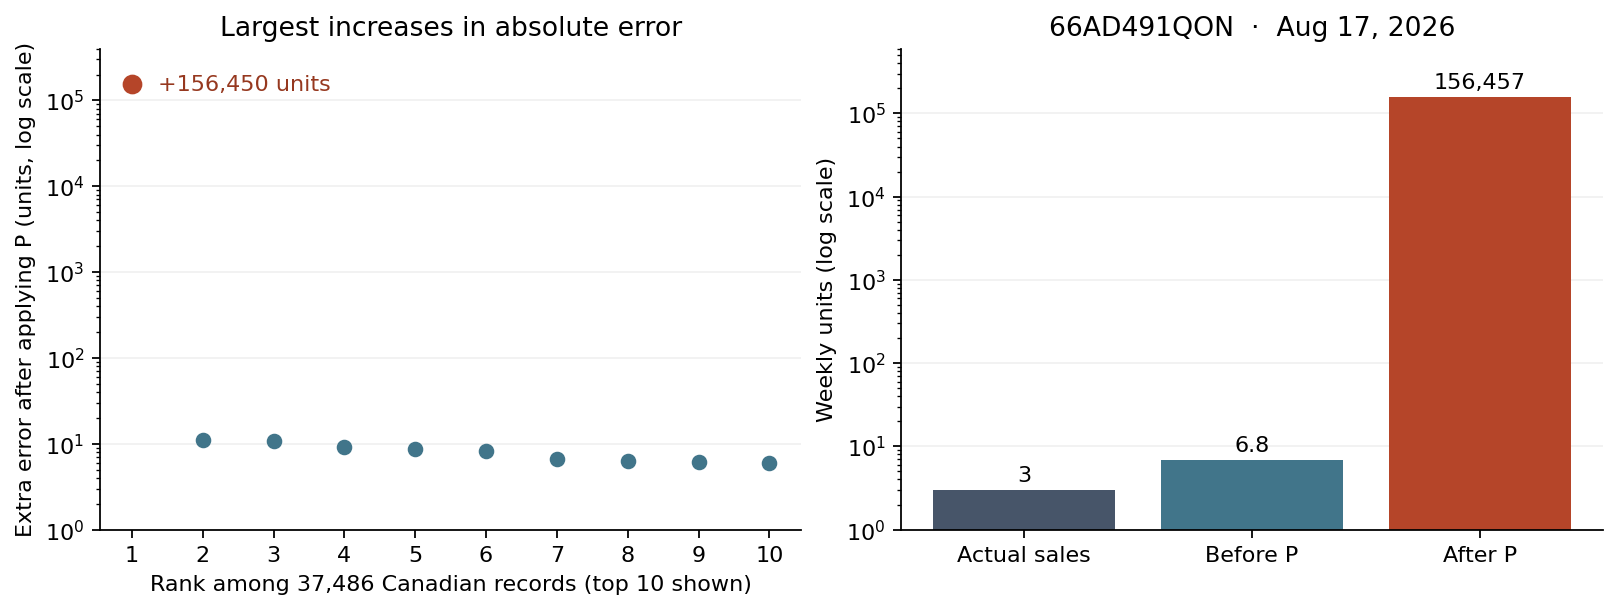

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

ca = price_check.loc[price_check.country.eq("CA")].sort_values("extra_error", ascending=False)
case = ca.iloc[0]
fig, (rank_ax, units_ax) = plt.subplots(1, 2, figsize=(10, 3.7), constrained_layout=True)
top = ca.head(10)
ranks = np.arange(1, len(top) + 1)
rank_ax.scatter(ranks[1:], top.extra_error.iloc[1:], color="#41758a", s=36)
rank_ax.scatter(1, case.extra_error, color="#b54529", s=62)
rank_ax.annotate(f"+{case.extra_error:,.0f} units", (1, case.extra_error),
                 xytext=(12,-3), textcoords="offset points", color="#96381f")
rank_ax.set(yscale="log", xticks=ranks, ylim=(1, 400000),
            title="Largest increases in absolute error",
            xlabel=f"Rank among {len(ca):,} Canadian records (top 10 shown)",
            ylabel="Extra error after applying P (units, log scale)")
values = [case.actual_units, case.BA, case.Q]
bars = units_ax.bar(["Actual sales", "Before P", "After P"], values,
                    color=["#475569", "#41758a", "#b54529"])
units_ax.set(yscale="log", ylim=(1, 600000), ylabel="Weekly units (log scale)",
             title=f"{case.product_id}  ·  {case.week_start:%b %d, %Y}")
for bar, value in zip(bars, values):
    units_ax.annotate(f"{value:,.0f}" if value >= 1000 or value == int(value) else f"{value:.1f}",
                      (bar.get_x()+bar.get_width()/2,value), xytext=(0,4),
                      textcoords="offset points", ha="center")
for ax in (rank_ax, units_ax):
    ax.grid(axis="y", alpha=.18)
    ax.set_axisbelow(True)
    ax.spines[["top","right"]].set_visible(False)
fig.savefig(out_dir / "canada_price_response_outlier.png", dpi=160, bbox_inches="tight")
plt.show()

**Why test a guardrail?** A single unusually cheap invoice can set the synthetic offer for a whole week. The demand model can then treat that offer as a deep discount and predict a sales increase far larger than past sales support. The next section checks both links: whether earlier SKU prices support the offer, and how far the model can reasonably extend its price response. We keep the extreme rows in the evaluation and compare errors on the same weeks to see whether the checks help. [Full-history predictions](pricewise_outputs/full_history_demand_predictions.csv)

## Design guardrails and refit the model



## Forecast Demand at Each Candidate Price

Export one row per market, SKU, segment, week, and candidate price, including the hold price. Show R, B, A, P, expected units (B × A × P), and the elasticity source so the dashboard can explain each price comparison.

## Pass Candidate Demand to the Pricing Engine

Use the demand prediction at each price, then apply available inventory, cost, and pricing rules to compare feasible choices with holding the current offer. Pass the recommended price, expected units sold, gross profit, and candidate comparisons to the dashboard. [price_engine.ipynb](price_engine.ipynb)

The existing scenario exports remain available while the weekly sales model and candidate-demand handoff are updated.